# ML Assignment 2 – MBTI Personality Classification (16 types)

### Trains 5 classifiers (Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes, SVM) on the Kaggle "Personality classification Data: 16 Personalities" dataset, evaluates them with 6 metrics, and saves the trained models into `model/` for the Streamlit app.

### MBTI stands for Myers-Briggs Type Indicator. It’s a personality questionnaire developed in the 1940s by Katharine Cook Briggs and her daughter Isabel Briggs Myers, based on Carl Jung’s ideas about psychological types. It sorts people into one of 16 types by placing them on one side of four pairs.
#### A type is one letter from each pair. for example: INTJ - means Introverted, iNtuitive, Thinking, Judging. That gives 2 × 2 × 2 × 2 = 16 combinations, which are the 16 classes in our target column.

In [2]:
#Environment check
import sys, platform, getpass, datetime
import sklearn, numpy, pandas, joblib
print("Run by      =", getpass.getuser())
print("Host        =", platform.node())
print("Run at      =", datetime.datetime.now())
print("Python      =", sys.version.split()[0])
print("scikit-learn=", sklearn.__version__)
print("numpy       =", numpy.__version__)
print("pandas      =", pandas.__version__)
print("joblib      =", joblib.__version__)

/home/s2026aj05610/anaconda3/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Run by      = s2026aj05610
Host        = ip-10-3-16-199.ap-south-1.compute.internal
Run at      = 2026-11-07 21:07:31.128193
Python      = 3.12.7
scikit-learn= 1.9.0
numpy       = 2.4.6
pandas      = 3.0.5
joblib      = 1.6.0


In [3]:
#Configuration
DATA_PATH    = "16P.csv"      # file from the Kaggle zip
TARGET_COLUMN   = "Personality"
DROP_COLS    = ["Response Id"]
TEST_SIZE    = 0.20
RANDOM_STATE = 42
MODEL_DIR    = "model"
TEST_CSV     = "test_data.csv"

In [4]:
#Imports
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.metrics import (accuracy_score, roc_auc_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef, classification_report)

os.makedirs(MODEL_DIR, exist_ok=True)

In [5]:
#Load data (the Kaggle file is not UTF-8, so trying few encodings)
def read_any(path):
    for enc in ("utf-8", "cp1252", "latin1"):
        try:
            return pd.read_csv(path, encoding=enc), enc
        except UnicodeDecodeError:
            continue
    raise ValueError("Could not decode file")

df, used_enc = read_any(DATA_PATH)
df.columns = [c.strip() for c in df.columns]
print("Encoding used:", used_enc)
print("Shape:", df.shape)
df.head()

Encoding used: cp1252
Shape: (59999, 62)


,Response Id,You regularly make new friends.,You spend a lot of your free time exploring various random topics that pique your interest,Seeing other people cry can easily make you feel like you want to cry too,You often make a backup plan for a backup plan.,"You usually stay calm, even under a lot of pressure","At social events, you rarely try to introduce yourself to new people and mostly talk to the ones you already know",You prefer to completely finish one project before starting another.,You are very sentimental.,You like to use organizing tools like schedules and lists.,...,You believe that pondering abstract philosophical questions is a waste of time.,"You feel more drawn to places with busy, bustling atmospheres than quiet, intimate places.",You know at first glance how someone is feeling.,You often feel overwhelmed.,You complete things methodically without skipping over any steps.,You are very intrigued by things labeled as controversial.,You would pass along a good opportunity if you thought someone else needed it more.,You struggle with deadlines.,You feel confident that things will work out for you.,Personality
0,0,0,0,0,0,0,1,1,0,0,...,0,0,0,-1,0,0,0,0,0,ENFP
1,1,0,0,-2,-3,-1,2,-2,0,3,...,0,-2,0,2,0,-1,-1,-1,3,ISFP
2,2,0,0,2,0,-1,2,0,0,1,...,0,2,0,2,-1,0,1,2,1,INFJ
3,3,0,-1,3,-1,0,0,-2,0,-2,...,0,0,-1,-1,0,1,0,-2,-1,ISTP
4,4,0,0,-1,0,2,-1,-2,0,1,...,0,1,0,2,0,1,-1,2,-1,ENFJ


Missing values: 0
Duplicate rows: 0
Number of features: 60
Number of classes : 16
Feature value range: -3 to 3


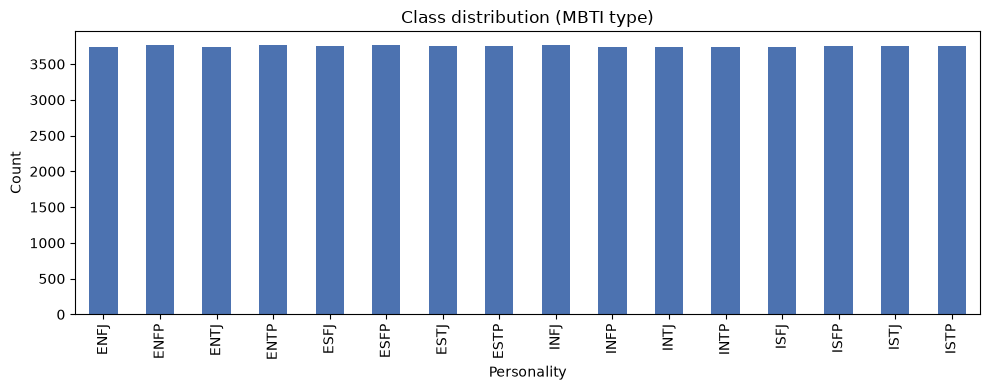

In [6]:
# Basic Data Analysis: missing values, duplicates, class balance, value range
print("Missing values:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
feature_cols = [c for c in df.columns if c not in DROP_COLS + [TARGET_COLUMN]]
print("Number of features:", len(feature_cols))
print("Number of classes :", df[TARGET_COLUMN].nunique())
print("Feature value range:", df[feature_cols].min().min(), "to", df[feature_cols].max().max())

plt.figure(figsize=(10, 4))
df[TARGET_COLUMN].value_counts().sort_index().plot(kind="bar", color="#4C72B0")
plt.title("Class distribution (MBTI type)")
plt.ylabel("Count"); plt.tight_layout(); plt.show()

In [7]:
# Clean and split (stratified, so all 16 types appear in train and test)
df = df.drop(columns=[c for c in DROP_COLS if c in df.columns]).dropna()
X = df[feature_cols]
y = df[TARGET_COLUMN].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

# Saving the held-out test set (features + target) for the GitHub repo and the Streamlit upload
test_df = X_test.copy()
test_df[TARGET_COLUMN] = y_test.values
test_df.to_csv(TEST_CSV, index=False, encoding="utf-8")
print("Saved", TEST_CSV)

Train: (47999, 60)  Test: (12000, 60)
Saved test_data.csv


In [8]:
# Defining the 5 models
# Scaling sits inside a Pipeline so the saved .pkl contains the scaler too (no separate artifact needed).
# SVM: RBF-SVC with probability=True is very slow on ~48k rows x 16 classes, so a linear SVM is used
# and wrapped in CalibratedClassifierCV to get class probabilities (needed for AUC).
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", LogisticRegression(max_iter=2000, C=1.0))]),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=20, min_samples_leaf=5, random_state=RANDOM_STATE),
    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", KNeighborsClassifier(n_neighbors=15, weights="distance"))]),
    "Naive Bayes": GaussianNB(),   # Gaussian: features are -3..+3 (negative values rule out Multinomial)
    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("clf", CalibratedClassifierCV(LinearSVC(C=0.5, dual=False, max_iter=5000), cv=3))]),
}

In [9]:
# Metric helper (multi-class: macro averages, one-vs-rest AUC)
def evaluate(model, X, y):
    y_pred = model.predict(X)
    y_prob = model.predict_proba(X)
    return {
        "Accuracy":  accuracy_score(y, y_pred),
        "AUC":       roc_auc_score(y, y_prob, multi_class="ovr", average="macro", labels=model.classes_),
        "Precision": precision_score(y, y_pred, average="macro", zero_division=0),
        "Recall":    recall_score(y, y_pred, average="macro", zero_division=0),
        "F1":        f1_score(y, y_pred, average="macro", zero_division=0),
        "MCC":       matthews_corrcoef(y, y_pred),
    }, y_pred

In [10]:
# Train, evaluate, save
FILE_NAMES = {
    "Logistic Regression": "logistic_regression.pkl",
    "Decision Tree": "decision_tree.pkl",
    "KNN": "knn.pkl",
    "Naive Bayes": "naive_bayes.pkl",
    "Support Vector Machine": "svm.pkl",
}
results, predictions = {}, {}
for name, model in models.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - t0
    metrics, y_pred = evaluate(model, X_test, y_test)
    results[name] = metrics
    predictions[name] = y_pred
    joblib.dump(model, os.path.join(MODEL_DIR, FILE_NAMES[name]), compress=3)
    print(f"{name:<24} trained in {train_time:6.1f}s | acc={metrics['Accuracy']:.4f}")

Logistic Regression      trained in    3.4s | acc=0.9183
Decision Tree            trained in    1.3s | acc=0.6488
KNN                      trained in    0.2s | acc=0.9870
Naive Bayes              trained in    0.2s | acc=0.9118
Support Vector Machine   trained in   30.7s | acc=0.9106


In [11]:
# Comparison table
results_df = pd.DataFrame(results).T.round(4)
results_df.index.name = "ML Model Name"
results_df.to_csv(os.path.join(MODEL_DIR, "metrics_summary.csv"))
results_df

,Accuracy,AUC,Precision,Recall,F1,MCC
ML Model Name,,,,,,
Logistic Regression,0.9183,0.9928,0.9183,0.9183,0.9182,0.9129
Decision Tree,0.6488,0.8649,0.6501,0.6487,0.6486,0.6254
KNN,0.9870,0.9947,0.9870,0.9870,0.9870,0.9861
Naive Bayes,0.9118,0.9926,0.9122,0.9118,0.9117,0.9060
Support Vector Machine,0.9106,0.9915,0.9104,0.9105,0.9104,0.9046


In [12]:
# Markdown version of the table 
header = "| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |\n|---|---|---|---|---|---|---|"
rows = [f"| {n} | " + " | ".join(f"{v:.4f}" for v in r.values) + " |" for n, r in results_df.iterrows()]
print("\n".join([header] + rows))

| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.9183 | 0.9928 | 0.9183 | 0.9183 | 0.9182 | 0.9129 |
| Decision Tree | 0.6488 | 0.8649 | 0.6501 | 0.6487 | 0.6486 | 0.6254 |
| KNN | 0.9870 | 0.9947 | 0.9870 | 0.9870 | 0.9870 | 0.9861 |
| Naive Bayes | 0.9118 | 0.9926 | 0.9122 | 0.9118 | 0.9117 | 0.9060 |
| Support Vector Machine | 0.9106 | 0.9915 | 0.9104 | 0.9105 | 0.9104 | 0.9046 |


In [13]:
# Saving metadata the Streamlit app uses to validate uploads
info = {
    "target_column": TARGET_COLUMN,
    "feature_columns": feature_cols,
    "classes": sorted(y.unique().tolist()),
    "model_files": FILE_NAMES,
    "sklearn_version": sklearn.__version__,
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),
}
with open(os.path.join(MODEL_DIR, "model_info.json"), "w") as f:
    json.dump(info, f, indent=2)
print(os.listdir(MODEL_DIR))
for f_ in os.listdir(MODEL_DIR):
    print(f"{f_:<28} {os.path.getsize(os.path.join(MODEL_DIR, f_))/1e6:7.2f} MB")

['model_info.json', 'knn.pkl', 'decision_tree.pkl', 'metrics_summary.csv', 'logistic_regression.pkl', 'naive_bayes.pkl', 'svm.pkl']
model_info.json                 0.01 MB
knn.pkl                         3.10 MB
decision_tree.pkl               0.27 MB
metrics_summary.csv             0.00 MB
logistic_regression.pkl         0.01 MB
naive_bayes.pkl                 0.02 MB
svm.pkl                         0.03 MB


In [14]:
# Markdown version of the table 
header = "| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |\n|---|---|---|---|---|---|---|"
rows = [f"| {n} | " + " | ".join(f"{v:.4f}" for v in r.values) + " |" for n, r in results_df.iterrows()]
print("\n".join([header] + rows))

| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.9183 | 0.9928 | 0.9183 | 0.9183 | 0.9182 | 0.9129 |
| Decision Tree | 0.6488 | 0.8649 | 0.6501 | 0.6487 | 0.6486 | 0.6254 |
| KNN | 0.9870 | 0.9947 | 0.9870 | 0.9870 | 0.9870 | 0.9861 |
| Naive Bayes | 0.9118 | 0.9926 | 0.9122 | 0.9118 | 0.9117 | 0.9060 |
| Support Vector Machine | 0.9106 | 0.9915 | 0.9104 | 0.9105 | 0.9104 | 0.9046 |


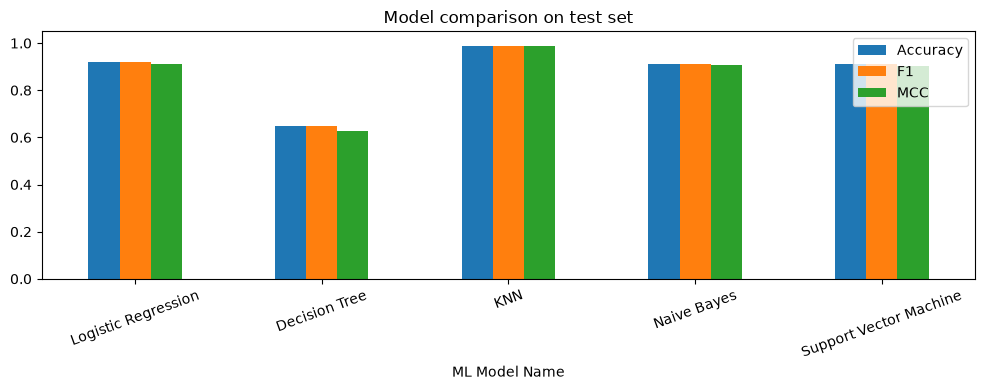

<Figure size 1000x800 with 0 Axes>

              precision    recall  f1-score   support

        ENFJ     0.9828    0.9907    0.9867       749
        ENFP     0.9919    0.9827    0.9873       752
        ENTJ     0.9893    0.9906    0.9900       747
        ENTP     0.9841    0.9894    0.9867       752
        ESFJ     0.9814    0.9866    0.9840       749
        ESFP     0.9920    0.9867    0.9894       754
        ESTJ     0.9946    0.9867    0.9907       752
        ESTP     0.9842    0.9947    0.9894       750
        INFJ     0.9933    0.9801    0.9866       752
        INFP     0.9801    0.9893    0.9847       747
        INTJ     0.9827    0.9853    0.9840       749
        INTP     0.9814    0.9880    0.9847       748
        ISFJ     0.9893    0.9866    0.9880       748
        ISFP     0.9852    0.9786    0.9819       749
        ISTJ     0.9906    0.9854    0.9880       751
        ISTP     0.9894    0.9907    0.9900       751

    accuracy                         0.9870     12000
   macro avg     0.9870   

In [15]:
# Visual comparison + confusion matrix of the best model (useful for your observations)
results_df[["Accuracy", "F1", "MCC"]].plot(kind="bar", figsize=(10, 4), ylim=(0, 1.05))
plt.title("Model comparison on test set"); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

best = results_df["MCC"].idxmax()
labels = sorted(y.unique())
plt.figure(figsize=(10, 8))
# sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
# plt.title(f"Confusion matrix - {best}"); plt.xlabel("Predicted"); plt.ylabel("Actual")
plt.tight_layout(); plt.show()
print(classification_report(y_test, predictions[best], digits=4))

In [16]:
#  Where does each model go wrong? (helps you write the observations table)
for name, y_pred in predictions.items():
    wrong = pd.Series(y_test.values[y_pred != y_test.values]).value_counts().head(3)
    print(f"{name:<24} errors={int((y_pred != y_test.values).sum()):5d}  most-missed: { {k: int(v) for k, v in wrong.items()} }")

Logistic Regression      errors=  980  most-missed: {'ESFJ': 109, 'ISFJ': 81, 'ISFP': 78}
Decision Tree            errors= 4215  most-missed: {'ISTP': 302, 'ISFP': 295, 'INTJ': 290}
KNN                      errors=  156  most-missed: {'ISFP': 16, 'INFJ': 15, 'ENFP': 13}
Naive Bayes              errors= 1058  most-missed: {'ESFJ': 135, 'ISTJ': 98, 'ISFP': 97}
Support Vector Machine   errors= 1073  most-missed: {'ESFJ': 129, 'ISFJ': 101, 'ISFP': 91}


In [17]:
# Writing to requirements.txt pinned to THIS environment's versions
import matplotlib, seaborn
reqs = [
    "streamlit>=1.30",
    f"scikit-learn=={sklearn.__version__}",
    f"numpy=={numpy.__version__}",
    f"pandas=={pandas.__version__}",
    f"joblib=={joblib.__version__}",
    f"matplotlib=={matplotlib.__version__}",
    f"seaborn=={seaborn.__version__}",
]
with open("requirements.txt", "w") as f:
    f.write("\n".join(reqs) + "\n")
print(open("requirements.txt").read())
print("On Streamlit Cloud > Advanced settings, choose Python", sys.version.split()[0][:4].rstrip("."))

streamlit>=1.30
scikit-learn==1.9.0
numpy==2.4.6
pandas==3.0.5
joblib==1.6.0
matplotlib==3.11.1
seaborn==0.13.2

On Streamlit Cloud > Advanced settings, choose Python 3.12
